**Предисловие**

Эту работу мучал как мог, но не смог достичь на kNN адекватных высот.

Основная проблема датасета - его синтетичность, это будет показано в одном из разделов работы.

# Описание набора данных

**Название:** Pegasus Spyware Attack Synthetic Dataset
**Источник:** [Kaggle — Pegasus Spyware Attack Synthetic Dataset](https://www.kaggle.com/datasets/krishna1502/pegasus-spyware-attacksynthetic-dataset)
**Размер:** 1000 записей, 17 признаков

### Содержание набора данных

Данный набор данных содержит синтетические логи активности устройств, имитирующие поведение, характерное для заражения вредоносным ПО Pegasus.
Он предназначен для обнаружения аномальной активности и экспериментов с моделями машинного обучения в области кибербезопасности.

Каждая строка соответствует одной записи (событию), зафиксированной системой мониторинга.

### Основные признаки

| Признак | Описание |
|----------|-----------|
| user_id | Уникальный идентификатор пользователя устройства |
| device_type | Тип устройства (смартфон, планшет и т. д.) |
| os_version | Версия операционной системы |
| app_usage_pattern | Характер использования приложений (например, интенсивность, категории приложений) |
| timestamp | Время активности |
| source_ip | Исходный IP-адрес соединения |
| destination_ip | Целевой IP-адрес |
| protocol | Используемый сетевой протокол |
| data_volume | Объём передаваемых данных |
| log_type | Тип логируемого события |
| event | Название события (например, доступ к файлу, сетевое подключение) |
| event_description | Текстовое описание события |
| error_code | Код ошибки (если применимо) |
| file_accessed | Имя или путь к файлу, к которому был произведён доступ |
| process | Название процесса, участвующего в событии |
| anomaly_detected | Признак наличия аномалии (например, "Suspicious File Access") |
| ioc | Индикатор компрометации (например, "Pegasus Signature", "Known Malicious IP") |

### Цель анализа

Целью проекта является обнаружение аномалий в поведении устройства, вызванных потенциальной активностью вредоносного ПО Pegasus.
Для этого используется модель машинного обучения, которая по характеристикам активности (сетевой трафик, типы процессов, логи и т.д.) должна предсказать наличие или отсутствие компрометации устройства.

### Целевая переменная

В качестве целевой переменной выбрана колонка, основанная на ioc - индикация компрометации. Это бинарный признак.
  - 1 — обнаружена компрометация устройства
  - 0 — компрометации не выявлено

Таким образом, задача сводится к бинарной классификации: анализ активности устройства и предсказание факта заражения.


In [1]:
import numpy as np  # Используется для численных вычислений и работы с массивами
import pandas as pd  # Используется для загрузки, обработки и анализа данных

# Загрузка датасета

In [2]:
import kagglehub # Используется для загрузки датасетов напрямую с Kaggle
from kagglehub import KaggleDatasetAdapter

def load_spyware_dataset():
    """
    Загружает датасет DDoS атак с Kaggle и создаёт случайную выборку.

    Функция загружает большой датасет по частям (chunks), из каждого chunk
    берёт случайные 10% строк для уменьшения размера данных, затем сохраняет
    в локальный CSV файл.

    Returns:
        pd.DataFrame: Датафрейм с выборкой данных (примерно 10% от исходного датасета).

    Example:
        >>> df = load_spyware_dataset()
        >>> print(f"Загружено строк: {len(df)}")
        Загружено строк: 22500
    """

    # Путь к файлу внутри датасета на Kaggle
    file_path = "synthetic_pegasus_dataset.csv"

    # Размер chunk для загрузки (100,000 строк за раз)
    # Используется для экономии оперативной памяти при работе с большими файлами

    # Загрузка датасета с Kaggle
    df = kagglehub.dataset_load(
        adapter=KaggleDatasetAdapter.PANDAS,        # adapter=PANDAS - загружаем как pandas DataFrame
        handle="krishna1502/pegasus-spyware-attacksynthetic-dataset",         # handle - уникальный идентификатор датасета на Kaggle (username/dataset-name)
        path=file_path,                             # path - путь к файлу внутри датасета на Kaggle
    )

    # Сохраняем результат в CSV файл для дальнейшего использования
    df.to_csv("dataset.csv", index=False) # index=False - не сохраняем индексы как отдельную колонку

    # Возвращаем готовый датафрейм
    return df

/Users/m.babushkin/Developer/SUSU.PE/venv_3.9/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [3]:
df: pd.DataFrame
try:
    df = pd.read_csv("dataset.csv")
except FileNotFoundError:
    df = load_spyware_dataset()

# Информация о датасете

In [4]:
df.head()

,user_id,device_type,os_version,app_usage_pattern,timestamp,source_ip,destination_ip,protocol,data_volume,log_type,event,event_description,error_code,file_accessed,process,anomaly_detected,ioc
0,1,iPhone,iOS 14.6,Low,2023-10-17 06:18:28,192.168.1.49,10.0.0.9,HTTPS,190,system,App Install,Event 793,423,/tmp/malware.bin,malware.exe,Unknown Process Execution,Pegasus Signature
1,1,iPhone,Android 10,Normal,2023-12-02 12:33:49,192.168.1.99,10.0.0.99,FTP,5845,application,System Update,Event 551,637,/var/log/syslog,chrome.exe,Unknown Process Execution,Pegasus Signature
2,1,iPhone,Android 11,Normal,2023-09-08 21:52:20,192.168.1.57,10.0.0.19,SSH,3629,application,Logout,Event 278,168,/var/log/syslog,malware.exe,Suspicious File Access,NaN
3,1,iPhone,Android 11,High,2023-12-07 11:41:16,192.168.1.51,10.0.0.2,FTP,4575,security,App Crash,Event 126,567,/home/user/docs/report.docx,malware.exe,High CPU Usage,Known Malicious IP
4,1,Android,iOS 14.6,Normal,2023-10-07 21:54:25,192.168.1.94,10.0.0.86,SSH,1607,system,Logout,Event 308,115,/tmp/malware.bin,systemd,NaN,Known Malicious IP


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            1000 non-null   int64 
 1   device_type        1000 non-null   object
 2   os_version         1000 non-null   object
 3   app_usage_pattern  1000 non-null   object
 4   timestamp          1000 non-null   object
 5   source_ip          1000 non-null   object
 6   destination_ip     1000 non-null   object
 7   protocol           1000 non-null   object
 8   data_volume        1000 non-null   int64 
 9   log_type           1000 non-null   object
 10  event              1000 non-null   object
 11  event_description  1000 non-null   object
 12  error_code         1000 non-null   int64 
 13  file_accessed      1000 non-null   object
 14  process            1000 non-null   object
 15  anomaly_detected   764 non-null    object
 16  ioc                698 non-null    object
d

# Подготовка данных в датасете

In [6]:
# user_id содержит уникальный идентификатор пользователя, что не несет ценности в рамках нашей задачи
# timestamp зачастую не несет информации, так как атака может быть совершена в любой момент, то было принято решение удалить данный признак полностью
# source_ip и destination_ip также зачастую не являются важными, поскольку атака может быть проведена откуда угодно и на какой угодно IP адрес
# event_description содержит код описания, самого описания в датасете нет, поэтому данный признак не несет ценности
# error_code и event_description содержит много уникальных значений, поэтому было принято решение их также убрать
# file_accessed содержит в себе название файла потенциальной угрозы, название может быть какое угодно - удаляем
# file_accessed содержит в себе название процесса потенциальной угрозы, название может быть какое угодно - удаляем
df.drop(['user_id', 'timestamp', 'source_ip', 'destination_ip', 'event_description', 'error_code', 'file_accessed', 'process'], axis=1, inplace=True)

In [7]:
df['anomaly_detected'] = df['anomaly_detected'].fillna('No')

In [8]:
df['ioc'] = df['ioc'].fillna('No')

In [9]:
df['is_compromised'] = np.where(df['ioc'] != 'No', True, False)
df.drop(columns=['ioc'], inplace=True)

In [10]:
df.head()

,device_type,os_version,app_usage_pattern,protocol,data_volume,log_type,event,anomaly_detected,is_compromised
0,iPhone,iOS 14.6,Low,HTTPS,190,system,App Install,Unknown Process Execution,True
1,iPhone,Android 10,Normal,FTP,5845,application,System Update,Unknown Process Execution,True
2,iPhone,Android 11,Normal,SSH,3629,application,Logout,Suspicious File Access,False
3,iPhone,Android 11,High,FTP,4575,security,App Crash,High CPU Usage,True
4,Android,iOS 14.6,Normal,SSH,1607,system,Logout,No,True


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   device_type        1000 non-null   object
 1   os_version         1000 non-null   object
 2   app_usage_pattern  1000 non-null   object
 3   protocol           1000 non-null   object
 4   data_volume        1000 non-null   int64 
 5   log_type           1000 non-null   object
 6   event              1000 non-null   object
 7   anomaly_detected   1000 non-null   object
 8   is_compromised     1000 non-null   bool  
dtypes: bool(1), int64(1), object(7)
memory usage: 63.6+ KB


In [12]:
def get_categorical_columns(dataframe):
    """
    Автоматическое определение категориальных столбцов.
    """
    return dataframe.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


def get_numerical_columns(dataframe):
    """
    Автоматическое определение числовых столбцов.
    """
    return dataframe.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns.tolist()

In [13]:
import matplotlib.pyplot as plt


def universal_hist(
    dataframe: pd.DataFrame,
    figsize=(15, 20),
    color_numeric='steelblue',
    color_categorical='coral',
):
    numeric_cols = get_numerical_columns(dataframe)
    categorical_cols = get_categorical_columns(dataframe)

    all_cols = numeric_cols + categorical_cols
    n_cols = len(all_cols)

    if n_cols == 0:
        return

    ncols = 3
    nrows = int(np.ceil(n_cols / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten() if n_cols > 1 else [axes]

    for idx, col in enumerate(all_cols):
        ax = axes[idx]

        if col in numeric_cols:
            # Числовая переменная - обычная гистограмма
            data = dataframe[col].dropna()
            ax.hist(data, color=color_numeric, alpha=0.7, edgecolor='black')

        else:
            # Категориальная переменная - bar chart
            value_counts = dataframe[col].value_counts(dropna=False)

            # Вертикальные
            bars = ax.bar(range(len(value_counts)), value_counts.values,
                         color=color_categorical, alpha=0.7, edgecolor='black')
            ax.set_xticks(range(len(value_counts)))
            ax.set_xticklabels(value_counts.index, rotation=45, ha='right', fontsize=8)

            # Значения на столбцах
            for i, v in enumerate(value_counts.values):
                ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8, fontweight='bold')

        # Заголовок
        ax.set_title(f'{col}',
                    fontsize=10, fontweight='bold', pad=10)
        ax.grid(alpha=0.3, linestyle='--')

    # Удаление пустых subplot'ов
    for idx in range(n_cols, len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

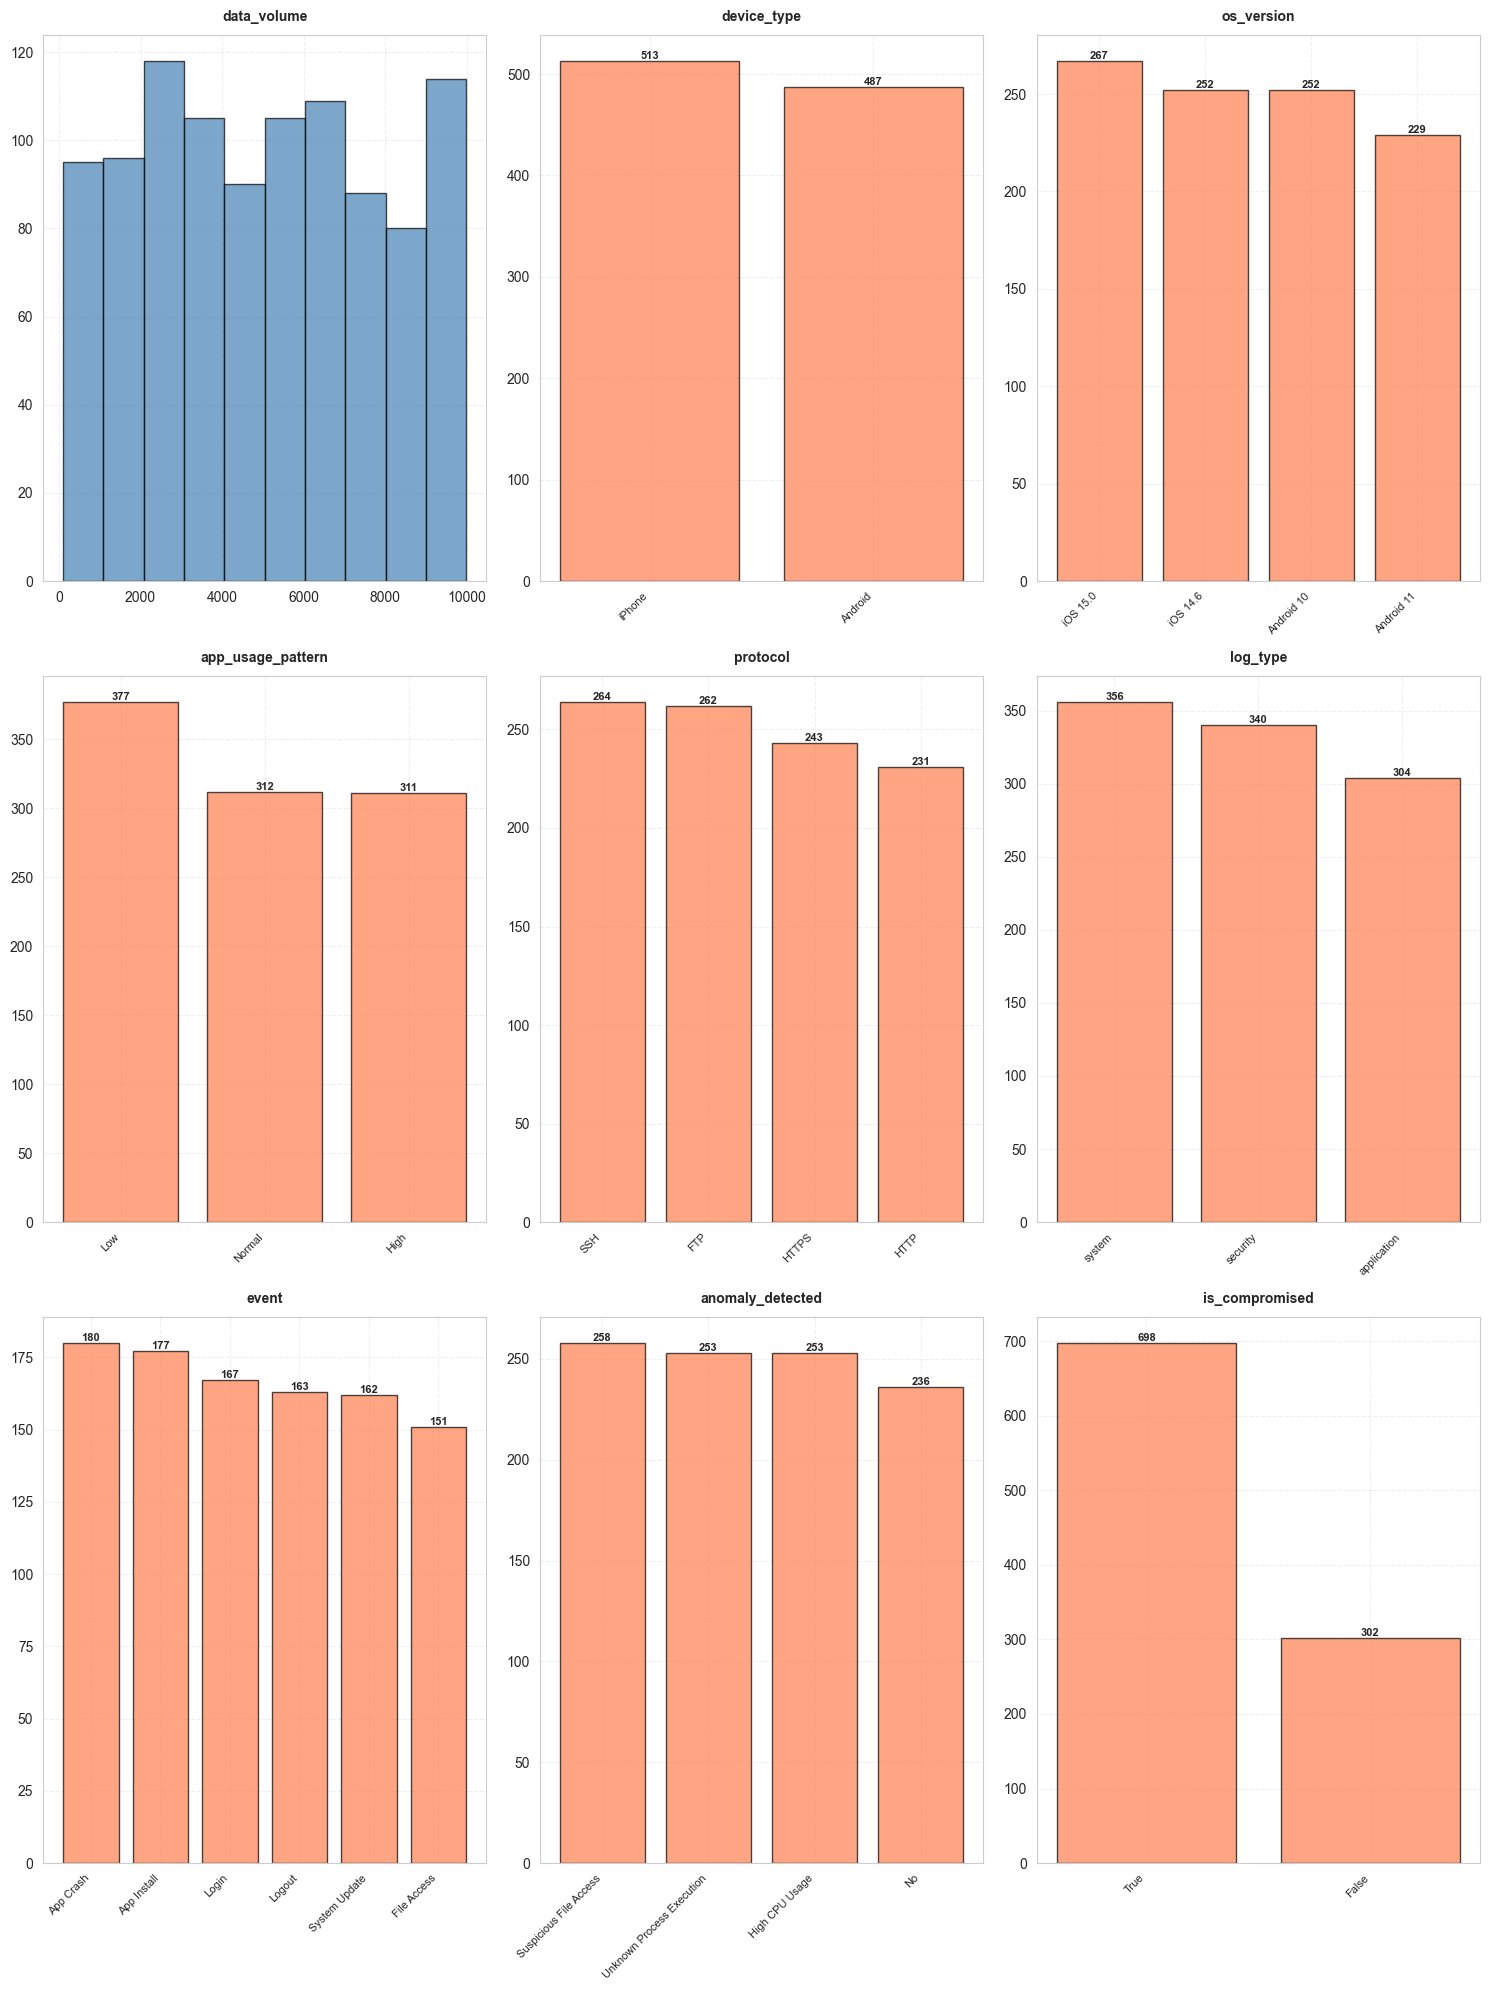

In [14]:
universal_hist(df)

## Небольшой прикол

Ну в целом эти данные развеселили. Однако это показывает качество этого синтетического датасета. И полное отсутствие в нем какой-либо логики.

Попытки логически фильтровать только совместимые с ОС марки телефонов не увенчались успехом. Если в датасете и есть какая-то логика, то как минимум от этого она не зависит.

In [15]:
device_os_compatibility = pd.crosstab(df['device_type'], df['os_version'])
device_os_compatibility

os_version,Android 10,Android 11,iOS 14.6,iOS 15.0
device_type,,,,
Android,122,111,132,122
iPhone,130,118,120,145


In [16]:
df.drop(columns=['device_type'], inplace=True)

# Выделение целевой переменной

In [17]:
# Многие признаки имеют тип данных object. Для работы с ними, их необходимо привести к числовому формату.
# Обработаем данные с помощью OneHotEncoding
# Такой подход берет признак с типом данных object и для каждого его варианта создает новый признак с бинарными значениями [True, False]
# Это позволяет избегать искусственного создания зависимости от порядка преобразованных значений.
X = pd.get_dummies(df.drop(columns=['is_compromised']), drop_first=True)
y = df['is_compromised']

In [18]:
X.head()

,data_volume,os_version_Android 11,os_version_iOS 14.6,os_version_iOS 15.0,app_usage_pattern_Low,app_usage_pattern_Normal,protocol_HTTP,protocol_HTTPS,protocol_SSH,log_type_security,log_type_system,event_App Install,event_File Access,event_Login,event_Logout,event_System Update,anomaly_detected_No,anomaly_detected_Suspicious File Access,anomaly_detected_Unknown Process Execution
0,190,False,True,False,True,False,False,True,False,False,True,True,False,False,False,False,False,False,True
1,5845,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,True
2,3629,True,False,False,False,True,False,False,True,False,False,False,False,False,True,False,False,True,False
3,4575,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False
4,1607,False,True,False,False,True,False,False,True,False,True,False,False,False,True,False,True,False,False


# Разделение датасета на обучающую, валидационную и тестовую выборки

In [19]:
# Импортируем функцию для разделения данных на обучающую и тестовую выборки
from sklearn.model_selection import train_test_split


def train_val_test_split(X, y, train_size=0.8, val_size=0.1, test_size=0.1, random_state=42):
    """
    Разделяет данные на train, validation и test наборы с сохранением пропорций классов.

    Args:
        X (pd.DataFrame): Матрица признаков.
        y (np.ndarray): Вектор целевой переменной.
        train_size (float): Доля данных для обучения. По умолчанию 0.6 (60%).
        val_size (float): Доля данных для валидации. По умолчанию 0.2 (20%).
        test_size (float): Доля данных для тестирования. По умолчанию 0.2 (20%).
        random_state (int): Seed для воспроизводимости результатов. По умолчанию 42.

    Returns:
        tuple: (X_train, X_val, X_test, y_train, y_val, y_test)
    """

    # Проверяем, что сумма пропорций равна 1.0 (100%). Если нет - выбрасываем ошибку AssertionError
    assert train_size + val_size + test_size == 1.0

    # Отделяем test set (20% от всех данных)
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y,                       # X_temp и y_temp содержат оставшиеся 80% данных (train + val)
        test_size=test_size,
        random_state=random_state,  # random_state - фиксируем генератор случайных чисел для воспроизводимости
        stratify=y,                 # stratify=y - сохраняем пропорции классов в обеих выборках
    )

    # Вычисляем долю validation от оставшихся данных
    # val_ratio = 0.2 / (0.6 + 0.2) = 0.25
    # Это означает: из 80% данных берём 25% на validation = 20% от всего датасета
    val_ratio = val_size / (train_size + val_size)

    # Делим оставшиеся данные на train и validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,             # test_size=val_ratio (0.25) означает 25% от X_temp идёт в validation. Остальные 75% от X_temp идут в train (что равно 60% от всего датасета)
        test_size=val_ratio,
        random_state=random_state,  # random_state - фиксируем генератор случайных чисел для воспроизводимости
        stratify=y_temp,            # stratify=y_temp - снова сохраняем пропорции классов
    )

    # Возвращаем все 3 набора данных
    # Train (80%) - для обучения модели
    # Val (10%) - для подбора гиперпараметров и промежуточной оценки
    # Test (10%) - для финальной оценки качества модели
    return X_train, X_val, X_test, y_train, y_val, y_test

In [20]:
# Разделяем выборку на 3 набора данных
X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(
    X, y,
    train_size=0.6,
    val_size=0.2,
    test_size=0.2,
    random_state=42,
)

# Train (60%) - для обучения модели
print(f"Train: {len(X_train)}")

# Val (20%) - для подбора гиперпараметров и финальной оценки на "боевых" данных
# Вообще валидационная выборка должна составляться вручную и должна быть очень маленькой, но у нас такой возможности нет
print(f"Val:   {len(X_val)}")

# Test (20%) - для оценки качества модели
print(f"Test:  {len(X_test)}")

Train: 600
Val:   200
Test:  200


# Оценка корреляции признаков и облечение модели

In [21]:
# Вычисляем матрицу корреляций между всеми числовыми признаками
# corr() - вычисляет корреляцию Пирсона между всеми парами колонок
# abs() - берём абсолютные значения корреляций (игнорируем знак)
corr_matrix = X_train.corr().abs()

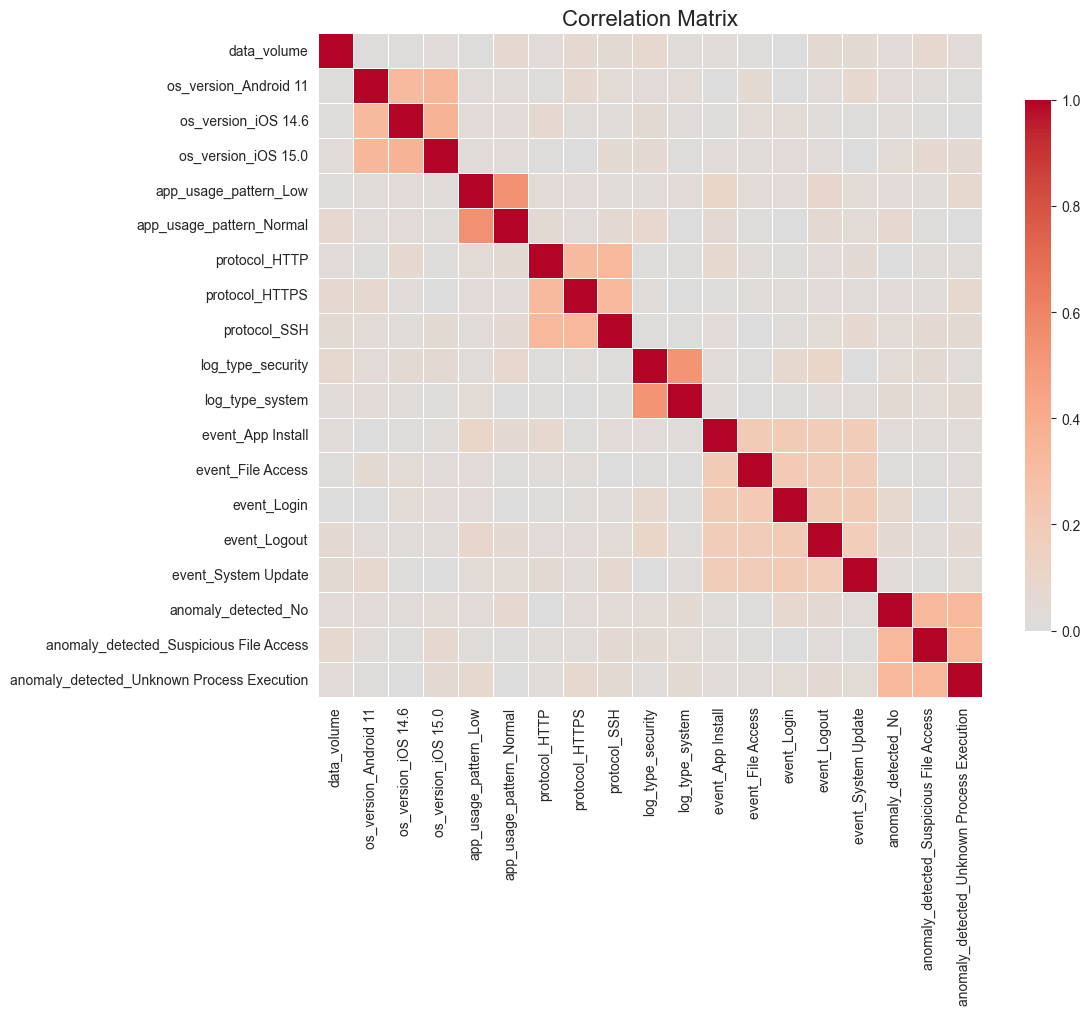

In [22]:
# Импортируем библиотеки для визуализации
import matplotlib.pyplot as plt  # Базовая библиотека для построения графиков
import seaborn as sns            # Библиотека для красивых статистических визуализаций

# Создаём фигуру (холст) размером 12x10 дюймов
plt.figure(figsize=(12, 10))

# Строим тепловую карту корреляционной матрицы
sns.heatmap(corr_matrix,
            annot=False,                # Не показывать числовые значения в ячейках (слишком много признаков)
            fmt='.2f',                  # Формат чисел - 2 знака после запятой (не используется при annot=False)
            cmap='coolwarm',            # Цветовая схема: синий (низкая корреляция) -> красный (высокая)
            center=0,                   # Центр шкалы в нуле (для симметричной палитры)
            square=True,                # Квадратные ячейки (пропорции 1:1)
            linewidths=0.5,             # Ширина линий между ячейками для разделения
            cbar_kws={"shrink": 0.8},   # Параметры цветовой шкалы (shrink - уменьшить на 20%)
)

# Добавляем заголовок графика
plt.title('Correlation Matrix', fontsize=16)

# Автоматически подгоняем размеры элементов, чтобы всё поместилось
plt.tight_layout()

# Отображаем график
plt.show()

In [23]:
# Создаём верхний треугольник корреляционной матрицы для избежания дублирования пар
# np.triu() - создаёт верхнюю треугольную матрицу (upper triangle)
# k=1 - начинаем с 1-й диагонали (исключаем главную диагональ, где корреляция = 1)
# astype(bool) - преобразуем в булеву маску (True/False)
# where() - оставляем значения только там, где маска True, остальное заменяется на NaN
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим признаки для удаления
# any() - возвращает True если хотя бы одно условие выполнено
to_drop = [column for column in upper.columns if any(upper[column] > 0.5)]

# Выводим количество признаков, которые будут удалены
print(f"Removing {len(to_drop)} correlated features (>0.5)")

# Удаляем высококоррелированные признаки из матрицы
X_train.drop(columns=to_drop, inplace=True)
X_val.drop(columns=to_drop, inplace=True)
X_test.drop(columns=to_drop, inplace=True)

# Выводим количество оставшихся признаков после фильтрации
print(f"Deleted columns: {to_drop}")
print(f"Remained features: {X_train.shape[1]}") # shape[1] - количество колонок (признаков)

Removing 2 correlated features (>0.5)
Deleted columns: ['app_usage_pattern_Normal', 'log_type_system']
Remained features: 17


# Подбор гиперпараметров

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    # Этап 1: Стандартизация признаков (приведение к нулевому среднему и единичной дисперсии)
    # Необходима для корректной работы KNN
    ('scaler', StandardScaler()),

    # Этап 2: Классификатор методом k ближайших соседей
    # Финальный алгоритм классификации
    ('knn', KNeighborsClassifier())
])

# Словарь с параметрами для перебора (поиска оптимальных значений)
param_grid = {
    # Количество соседей для KNN (сколько ближайших точек учитывать)
    'knn__n_neighbors': range(1, 31),

    # Способ взвешивания соседей:
    # 'uniform' - все соседи имеют одинаковый вес
    # 'distance' - вес обратно пропорционален расстоянию
    'knn__weights': ['uniform', 'distance'],

    # Различные метрики расстояния
    'knn__metric': ['euclidean', 'manhattan', 'minkowski']
}

# Создание объекта для поиска оптимальных гиперпараметров по сетке
# Всего будет проверено 30 × 2 × 3 = 180 комбинаций параметров
grid_search = GridSearchCV(
    pipeline,              # Конвейер для оптимизации
    param_grid,            # Сетка параметров для перебора
    cv=5,                  # Количество блоков для кросс-валидации (5-fold CV)
    scoring='accuracy',    # Метрика оптимизации (accuracy)
    n_jobs=-1,             # Использовать все доступные процессоры для ускорения
    verbose=2,             # Уровень детализации вывода (2 = подробный)
)

In [25]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 180 candidates, totalling 900 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'knn__metric': ['euclidean', 'manhattan', 'minkowski'],
                         'knn__n_neighbors': range(1, 31),
                         'knn__weights': ['uniform', 'distance']},
             scoring='accuracy', verbose=2)

In [26]:
print(f"Best parameteres: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")

Best parameteres: {'knn__metric': 'euclidean', 'knn__n_neighbors': 29, 'knn__weights': 'uniform'}
Best CV score: 0.7067


# kNN модель

In [27]:
model = Pipeline([
    # Этап 1: Стандартизация признаков (приведение к нулевому среднему и единичной дисперсии)
    # Необходима для корректной работы KNN
    ('scaler', StandardScaler()),

    # Этап 2: Классификатор методом k ближайших соседей
    # Финальный алгоритм классификации
    ('knn', KNeighborsClassifier(n_neighbors=29, weights='uniform', metric='euclidean'))
])
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('knn',
                 KNeighborsClassifier(metric='euclidean', n_neighbors=29))])

# Проверка на тестовых данных

In [28]:
# Предсказываем значения на тестовой выборке
y_test_pred = model.predict(X_test)

In [29]:
# Импорт функции для создания подробного отчёта о качестве классификации
from sklearn.metrics import classification_report

# Вывод подробного отчёта о классификации
# classification_report() создаёт таблицу с метриками качества для каждого класса:
#
# Параметры:
#   y_test - истинные метки классов (правильные ответы)
#   y_test_pred - предсказанные моделью метки классов
#   digits=4 - количество знаков после запятой для отображения метрик
#
# Отчёт включает для каждого класса:
#   - precision (точность) - доля правильных среди предсказанных как этот класс
#   - recall (полнота) - доля найденных объектов класса среди всех объектов класса
#   - f1-score - гармоническое среднее между precision и recall
#   - support - количество объектов данного класса в тестовой выборке
#
# Также показывает общие метрики:
#   - accuracy - общая точность модели
#   - macro avg - простое среднее метрик по всем классам
#   - weighted avg - взвешенное среднее (учитывает количество объектов каждого класса)
print(classification_report(y_test, y_test_pred, digits=4))

              precision    recall  f1-score   support

       False     0.1667    0.0167    0.0303        60
        True     0.6959    0.9643    0.8084       140

    accuracy                         0.6800       200
   macro avg     0.4313    0.4905    0.4193       200
weighted avg     0.5371    0.6800    0.5750       200



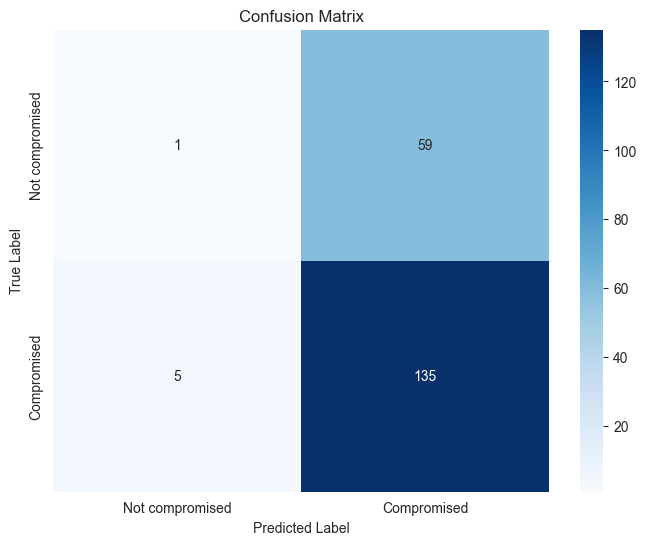

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns # библиотека для отображения красивых графиков
import matplotlib.pyplot as plt

# Вычисление матрицы ошибок
cm = confusion_matrix(y_test, y_test_pred)

# Создание графика
plt.figure(figsize=(8, 6))

# Построение тепловой карты
sns.heatmap(
    cm,
    annot=True,                                     # Показывать значения в ячейках
    fmt='d',                                        # Формат: целые числа
    cmap='Blues',                                   # Цветовая палитра: синие оттенки
    xticklabels=['Not compromised','Compromised'],  # Метки столбцов (что предсказала модель)
    yticklabels=['Not compromised','Compromised'],  # Метки строк (что на самом деле)
)

# Настройка заголовков и подписей осей
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Отображение графика
plt.show()

# Проверка на валидационных данных

In [31]:
# Предсказываем значения на валидационной выборке
y_val_pred = model.predict(X_val)

In [32]:
# Вывод подробного отчёта о классификации
# classification_report() создаёт таблицу с метриками качества для каждого класса:
#
# Параметры:
#   y_val - истинные метки классов (правильные ответы)
#   y_val_pred - предсказанные моделью метки классов
#   digits=4 - количество знаков после запятой для отображения метрик
#
# Отчёт включает для каждого класса:
#   - precision (точность) - доля правильных среди предсказанных как этот класс
#   - recall (полнота) - доля найденных объектов класса среди всех объектов класса
#   - f1-score - гармоническое среднее между precision и recall
#   - support - количество объектов данного класса в тестовой выборке
#
# Также показывает общие метрики:
#   - accuracy - общая точность модели
#   - macro avg - простое среднее метрик по всем классам
#   - weighted avg - взвешенное среднее (учитывает количество объектов каждого класса)
print(classification_report(y_val, y_val_pred, digits=4))

              precision    recall  f1-score   support

       False     0.5000    0.0328    0.0615        61
        True     0.6990    0.9856    0.8179       139

    accuracy                         0.6950       200
   macro avg     0.5995    0.5092    0.4397       200
weighted avg     0.6383    0.6950    0.5872       200



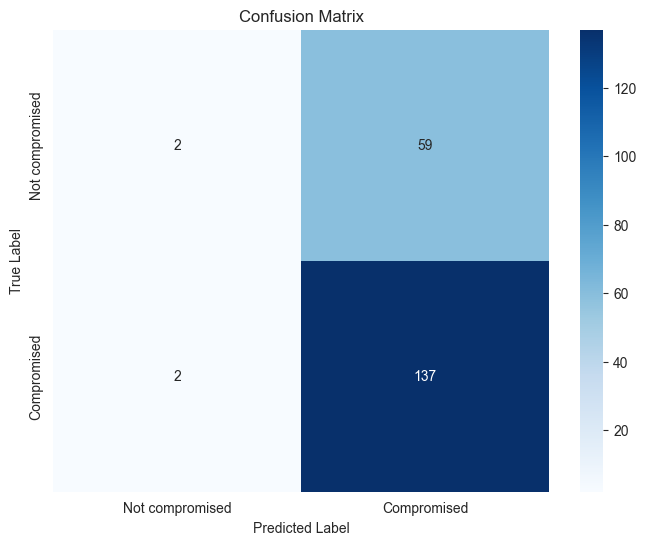

In [33]:
from sklearn.metrics import confusion_matrix
import seaborn as sns # библиотека для отображения красивых графиков
import matplotlib.pyplot as plt

# Вычисление матрицы ошибок
cm = confusion_matrix(y_val, y_val_pred)

# Создание графика
plt.figure(figsize=(8, 6))

# Построение тепловой карты
sns.heatmap(
    cm,
    annot=True,                                     # Показывать значения в ячейках
    fmt='d',                                        # Формат: целые числа
    cmap='Blues',                                   # Цветовая палитра: синие оттенки
    xticklabels=['Not compromised','Compromised'],  # Метки столбцов (что предсказала модель)
    yticklabels=['Not compromised','Compromised'],  # Метки строк (что на самом деле)
)

# Настройка заголовков и подписей осей
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# Отображение графика
plt.show()

# Выводы

Какой датасет - такая и модель :)

Проблемы у модели заключаются в банальном отсутствии адекватных данных для обучения. Есть подозрение, что датасет собирался перебором всех значений. Оттого и явный перекос в обучении модели.

Попытка сделать oversampling или сбалансировать классы приводит к тому, что модель перестает предсказывать в целом.

Попытка сделать undersampling приводит к недообучению модели.

Попытка сделать target encoding вместо one-hot encoding не приводит к каким-либо результатам. Модель предсказывает все так же не очень.

`Как минимум модель будет всегда сигнализировать о компрометации, хоть и в 30% случаев это ложная тревога lol`